# DATA3001 Phase 1 — Region and Data Audit

**Purpose.** Test whether the proposed source, transition and downstream zones contain enough independent Global Drifter Program trajectories for exact 7-day and 30-day endpoint analysis. This notebook is a screening audit; it does not select or fit a prediction model.

The three analytical zones are:

1. **North-Central Gulf** — candidate offshore-source zone.
2. **Florida-Bahamas** — transition zone around the Florida Straits and Bahamas.
3. **Gulf Stream Corridor** — downstream western North Atlantic corridor.

These are reproducible screening geometries, not claims that the connected ocean system has hard boundaries.

## Evidence and definitions

- NOAA GDP data access: https://www.aoml.noaa.gov/phod/gdp/data.php
- NOAA Loop Current overview: https://oceanservice.noaa.gov/facts/loopcurrent.html
- BOEM/BSEE OCS drilling-platform layer: https://gis.boem.gov/arcgis/rest/services/BOEM_BSEE/GOA_Layers/MapServer/0
- Full local receipt: [`SOURCE_RECEIPT.md`](SOURCE_RECEIPT.md)

An **entering trajectory** has at least one finite position inside a zone. A trajectory is **7-day-valid** or **30-day-valid** only when the same six-hour trajectory has a finite endpoint at the exact horizon. The endpoint may leave the origin zone; leaving is not treated as data loss. Counts are unique trajectories, not six-hour observations.

Regional totals overlap when the same trajectory enters more than one functional zone and must not be summed. At cell level, a trajectory is counted once per 1° origin cell. A trajectory can therefore contribute to more than one cell if it traverses several cells. The threshold of 25 valid 30-day trajectories is a transparent screening threshold, not a statistical guarantee.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

import pandas as pd
from IPython.display import Image, display

repo_root = Path.cwd()
if repo_root.name == "analysis":
    repo_root = repo_root.parent
analysis_dir = repo_root / "analysis"
output_dir = analysis_dir / "outputs"

source_root = Path(os.environ.get(
    "GDP_AUDIT_SOURCE_ROOT",
    "/Users/moonedgethug/Documents/Codex/2026-09-14/referenced-chatgpt-conversation-this-is-an/work/region-selection/global_audit/derived_may25",
))
land_shapefile = Path(os.environ.get(
    "GDP_AUDIT_LAND_SHAPEFILE",
    "/Users/moonedgethug/Documents/Codex/2026-09-14/referenced-chatgpt-conversation-this-is-an/work/region-selection/naturalearth/ne_110m_land/ne_110m_land.shp",
))
boem_platforms = output_dir / "boem-current-platforms.geojson"

required = [source_root / "array_cache", source_root / "source_manifest.json", land_shapefile, boem_platforms]
missing = [str(path) for path in required if not path.exists()]
assert not missing, "Missing audit inputs:\n" + "\n".join(missing)

command = [
    sys.executable,
    str(analysis_dir / "region_data_audit.py"),
    "--cache-dir", str(source_root / "array_cache"),
    "--source-manifest", str(source_root / "source_manifest.json"),
    "--land-shapefile", str(land_shapefile),
    "--boem-platforms", str(boem_platforms),
    "--output-dir", str(output_dir),
]
result = subprocess.run(command, check=True, capture_output=True, text=True)
print(result.stdout.split("{", 1)[0].strip())

region  entering_trajectories  valid_7d_trajectories  valid_7d_pct  valid_30d_trajectories  valid_30d_pct  valid_both_trajectories  valid_both_pct  drogued_valid_30d_trajectories  drogued_share_of_valid30_pct  one_degree_cells_touched  cells_valid30_ge_10  cells_valid30_ge_25  cells_valid30_ge_50  median_valid30_per_touched_cell  top_experiment_share_valid30  top_year_share_valid30  complexity_cells_ge25  median_effective_30d_destination_cells_ge25  median_direction_concentration_30d_ge25  median_outside_region_share_30d_ge25
  North-Central Gulf                    288                    278      0.965278                     225       0.781250                      225        0.781250                             110                      0.488889                        40                   36                   30                   21                             51.0                      0.235556                0.155556                     30                                    34.645750  

## Region-level support

In [2]:
summary = pd.read_csv(output_dir / "region-audit-summary.csv")
summary_display = summary[[
    "region", "entering_trajectories", "valid_7d_trajectories", "valid_7d_pct",
    "valid_30d_trajectories", "valid_30d_pct", "drogued_valid_30d_trajectories",
    "one_degree_cells_touched", "cells_valid30_ge_25", "median_valid30_per_touched_cell",
]].copy()
summary_display["valid_7d_pct"] = (100 * summary_display["valid_7d_pct"]).round(1)
summary_display["valid_30d_pct"] = (100 * summary_display["valid_30d_pct"]).round(1)
summary_display

,region,entering_trajectories,valid_7d_trajectories,valid_7d_pct,valid_30d_trajectories,valid_30d_pct,drogued_valid_30d_trajectories,one_degree_cells_touched,cells_valid30_ge_25,median_valid30_per_touched_cell
0,North-Central Gulf,288,278,96.5,225,78.1,110,40,30,51.0
1,Florida-Bahamas,782,736,94.1,613,78.4,376,71,42,56.0
2,Gulf Stream Corridor,1117,1092,97.8,1044,93.5,711,137,127,132.0


## Grid-resolution sensitivity

The same trajectory archive is screened at four cell sizes. This is a data-support sensitivity analysis, not a model-resolution choice.

In [3]:
grid_sensitivity = pd.read_csv(output_dir / "region-audit-grid-sensitivity.csv")
grid_sensitivity

,region,grid_resolution_degrees,cells_touched,cells_valid7_ge_10,cells_valid30_ge_10,cells_valid30_ge_25,cells_valid30_ge_50,cells_drogued_valid30_ge_25,median_valid30_per_touched_cell,median_drogued_valid30_per_touched_cell
0,North-Central Gulf,0.25,561,451,434,162,0,0,19.0,8.0
1,North-Central Gulf,0.50,144,127,118,92,28,28,32.5,15.0
2,North-Central Gulf,1.00,40,36,36,30,21,19,51.0,23.5
3,North-Central Gulf,2.00,15,15,15,13,10,9,75.0,34.0
4,Florida-Bahamas,0.25,891,554,517,379,217,233,16.0,9.0
5,Florida-Bahamas,0.50,245,169,156,125,100,106,27.0,16.0
6,Florida-Bahamas,1.00,71,55,51,42,37,37,56.0,33.0
7,Florida-Bahamas,2.00,24,22,21,19,17,17,105.0,57.0
8,Gulf Stream Corridor,0.25,1869,1738,1729,1568,839,953,47.0,25.0
9,Gulf Stream Corridor,0.50,493,466,463,442,399,414,83.0,44.0


In [4]:
checks = pd.read_json(output_dir / "region-audit-checks.json", typ="series")
assert bool(checks["ragged_lengths_match"])
assert bool(checks["region_counts_nested"])
assert bool(checks["drogued_counts_bounded"])
checks

source_trajectory_rows            28728
source_distinct_ids               28728
source_observation_rows        48887074
ragged_lengths_match                  1
region_counts_nested                  1
drogued_counts_bounded                1
grid_counts_nested                    1
grid_drogued_counts_bounded           1
dtype: int64

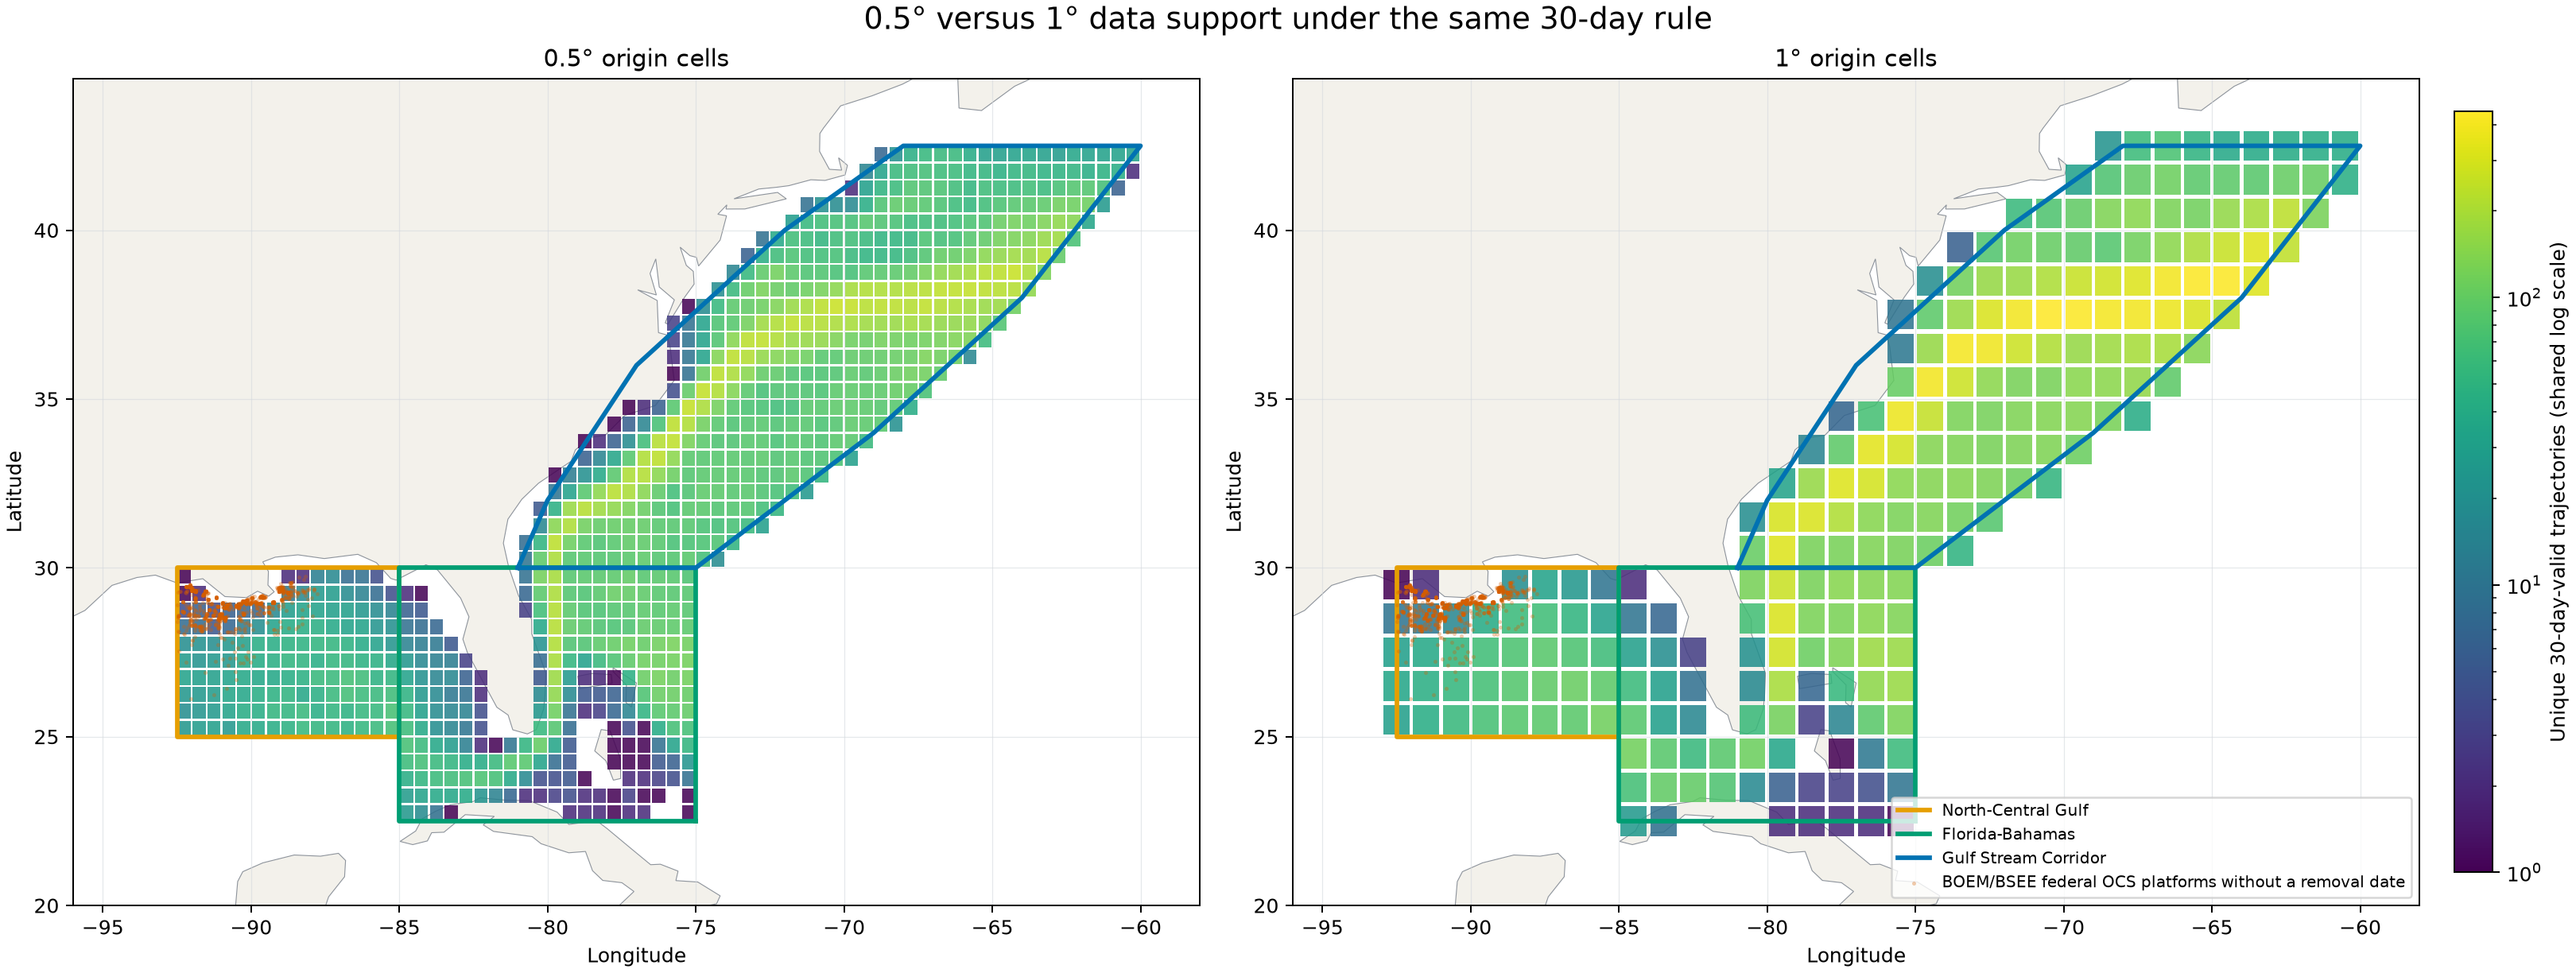

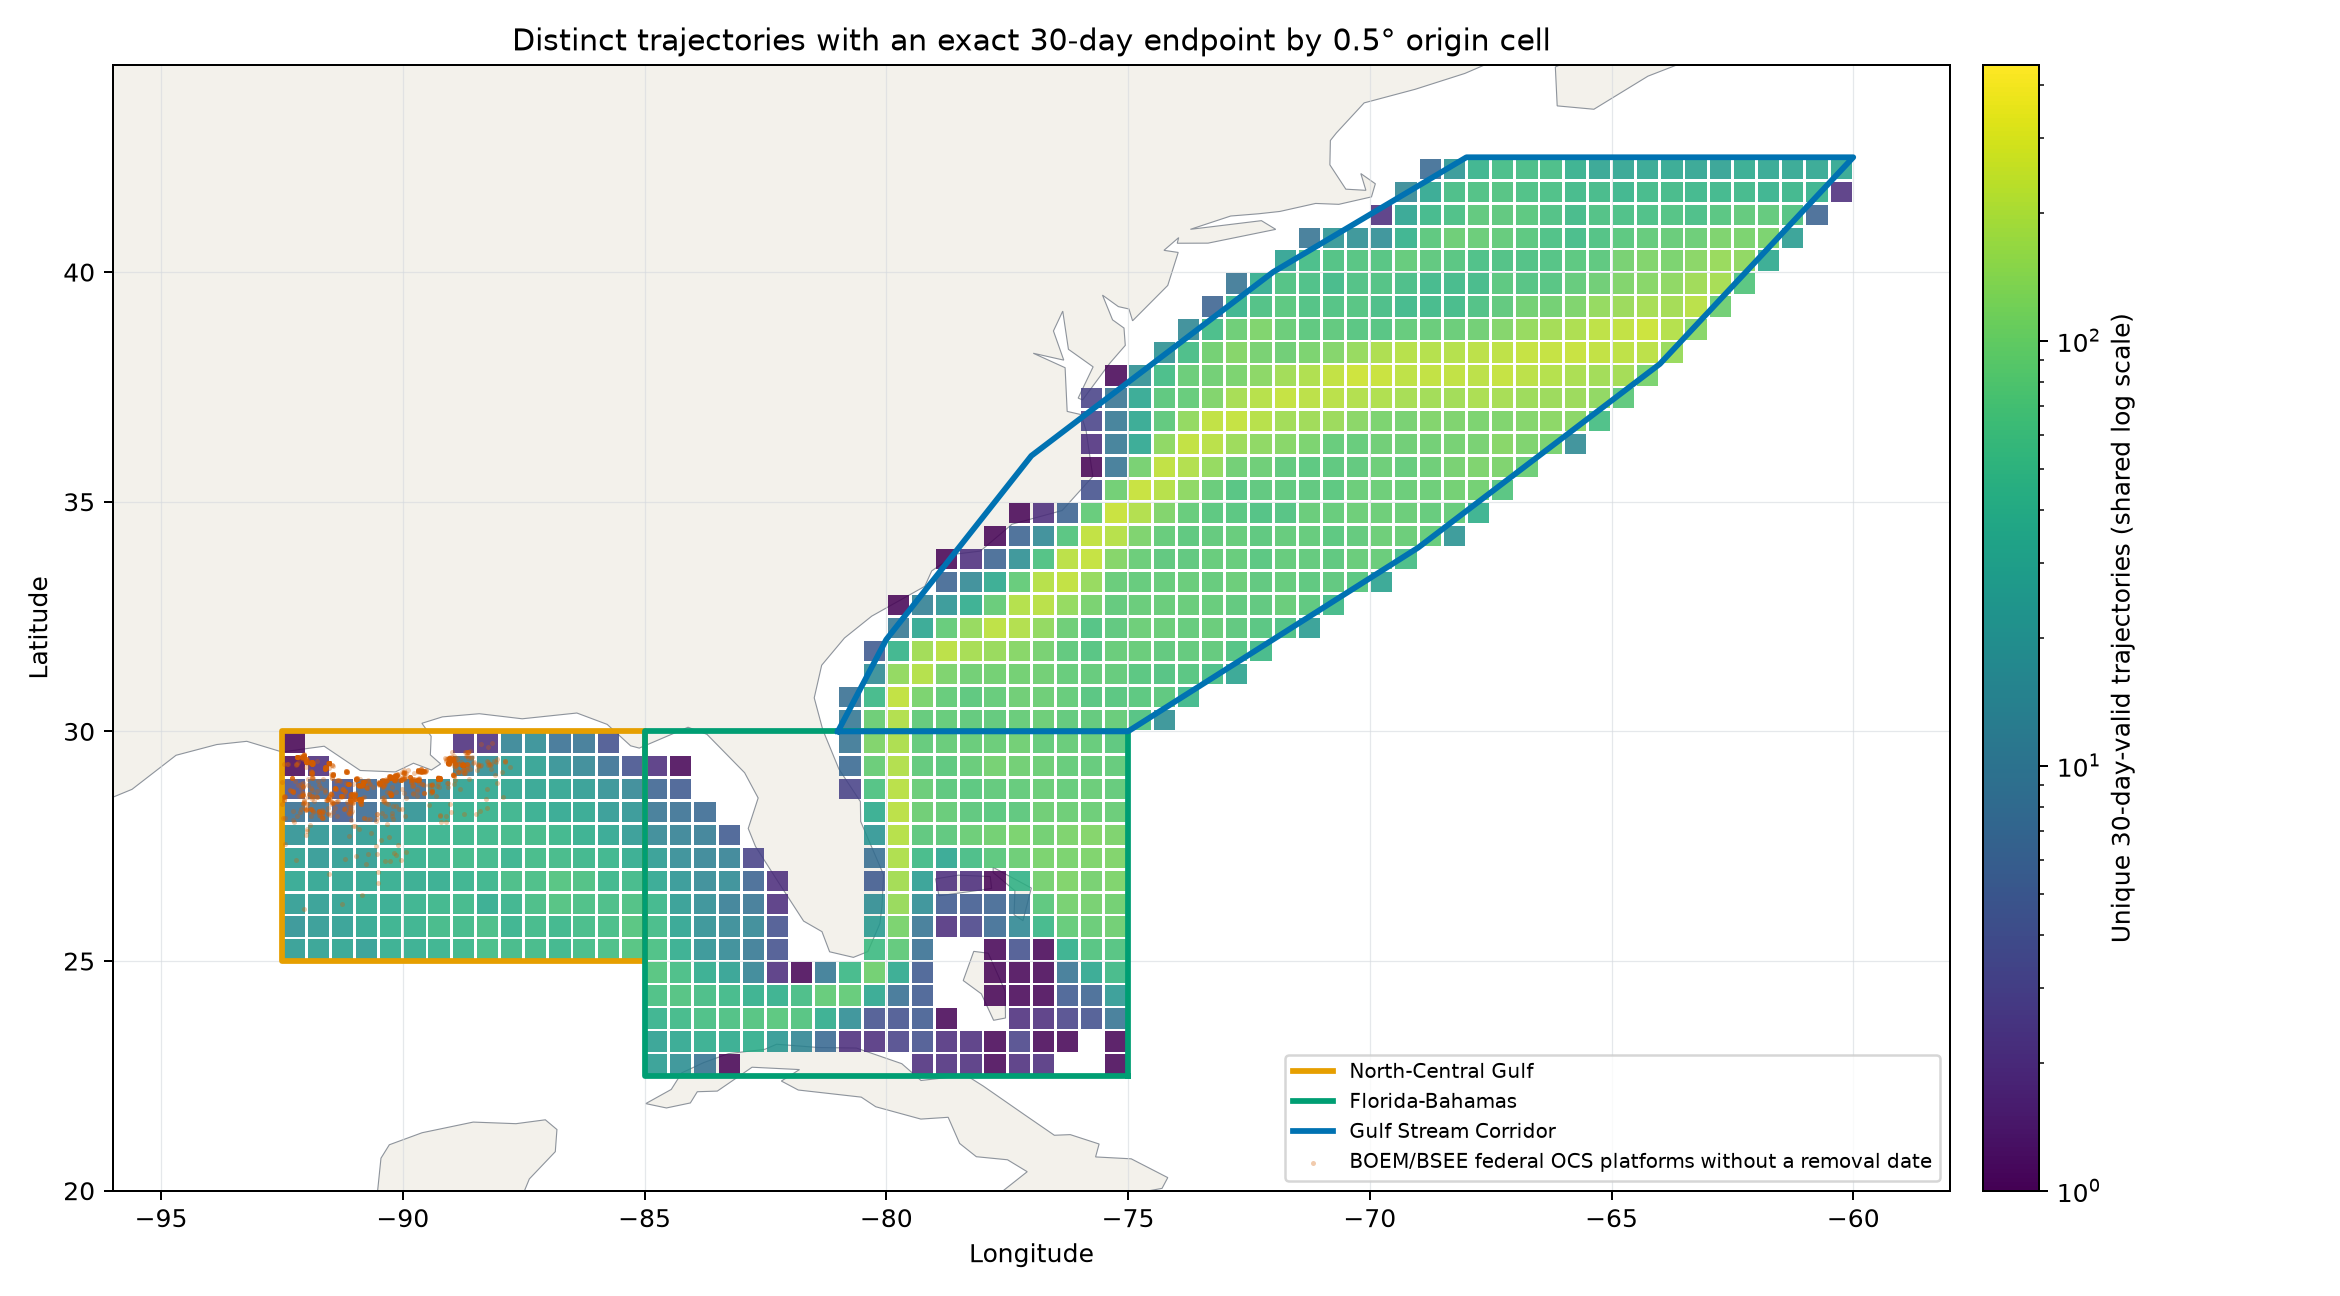

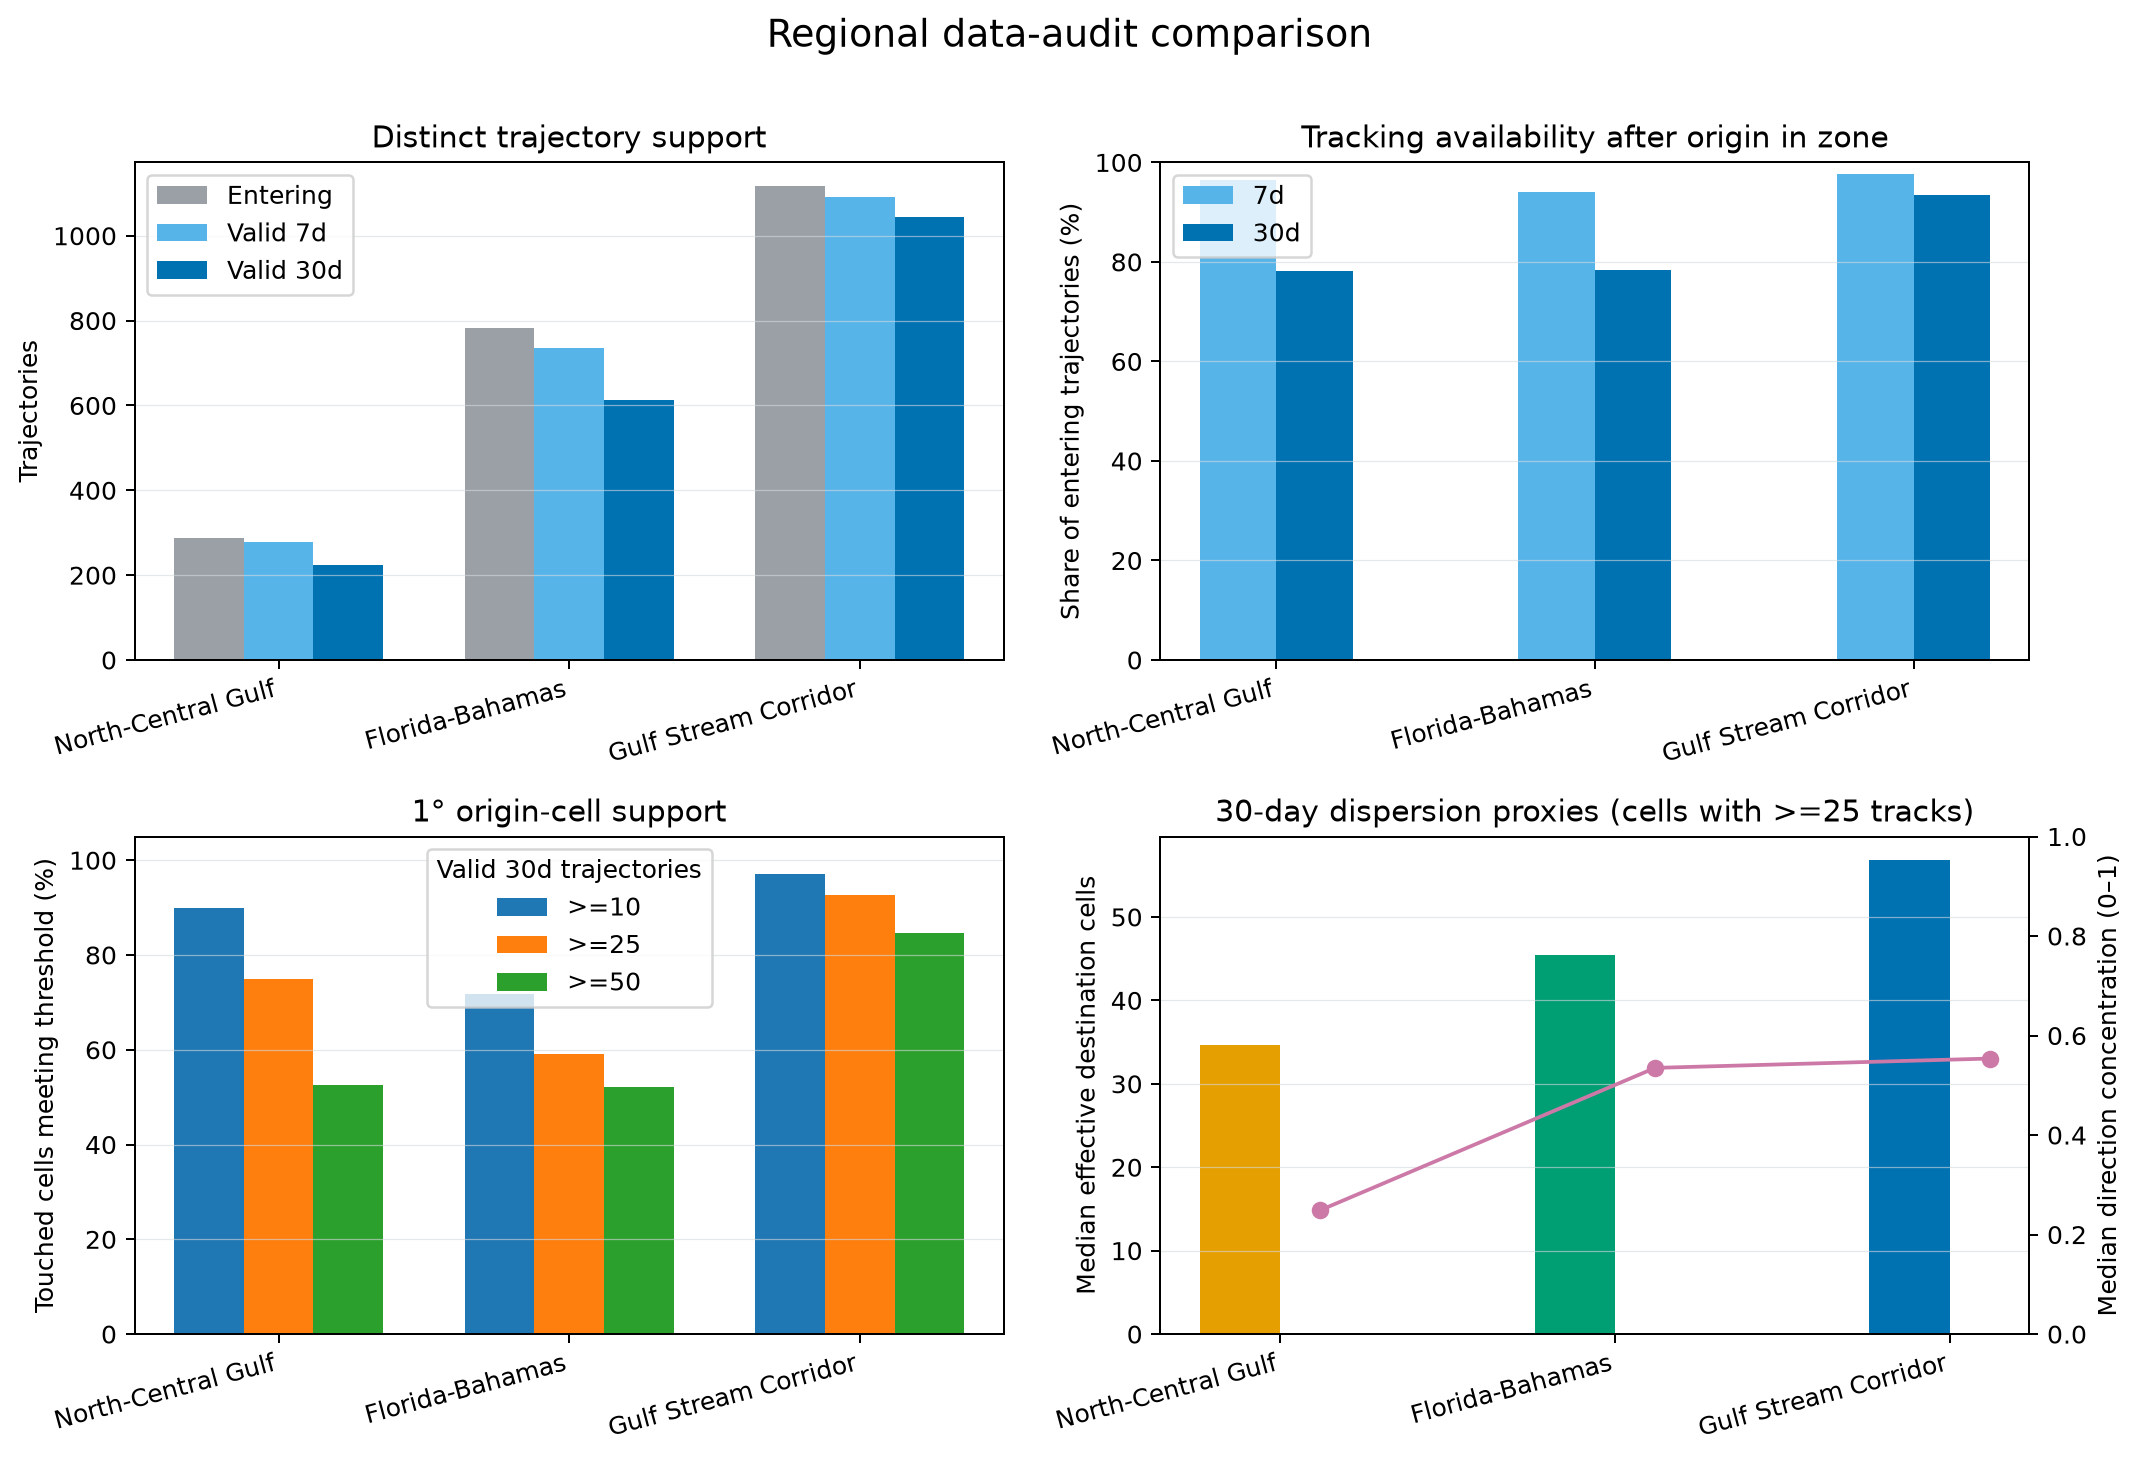

In [5]:
display(Image(filename=str(output_dir / "region-audit-map-0p5-vs-1deg.png")))
display(Image(filename=str(output_dir / "region-audit-map-0p5.png")))
display(Image(filename=str(output_dir / "region-audit-comparison.png")))

## North-Central Gulf application/data overlap

BOEM/BSEE platform points are application-context evidence, not trajectory data. The table below keeps only 1° cells that contain at least one platform and at least 25 unique 30-day-valid trajectories. It reports raw support plus temporal, experiment and drogue-status checks; no weighted score is imposed.

In [6]:
overlap = pd.read_csv(output_dir / "north-central-gulf-platform-cell-overlap.csv")
eligible = overlap[(overlap["current_platforms"] > 0) & (overlap["valid_30d_trajectories"] >= 25)].copy()
columns = [
    "lon_min", "lon_max", "lat_min", "lat_max", "current_platforms",
    "entering_trajectories", "valid_7d_trajectories", "valid_30d_trajectories",
    "drogued_valid_30d_trajectories", "first_valid_30d_year", "last_valid_30d_year",
    "active_valid_30d_years", "top_year_share_valid_30d", "top_season_share_valid_30d",
    "top_experiment_share_valid_30d", "effective_30d_destination_cells",
    "direction_concentration_30d",
]
eligible[columns].sort_values(["valid_30d_trajectories", "current_platforms"], ascending=False)

,lon_min,lon_max,lat_min,lat_max,current_platforms,entering_trajectories,valid_7d_trajectories,valid_30d_trajectories,drogued_valid_30d_trajectories,first_valid_30d_year,last_valid_30d_year,active_valid_30d_years,top_year_share_valid_30d,top_season_share_valid_30d,top_experiment_share_valid_30d,effective_30d_destination_cells,direction_concentration_30d
16,-90,-89,27,28,1,82,78,66,33,1999.0,2024.0,18,0.136364,0.333333,0.257576,38.515322,0.258879
17,-88,-87,28,29,1,93,87,65,31,1999.0,2024.0,18,0.261538,0.400000,0.230769,31.103223,0.320268
10,-89,-88,28,29,12,81,75,60,31,1999.0,2024.0,18,0.266667,0.383333,0.233333,27.599481,0.331133
13,-91,-90,26,27,3,62,60,54,25,2000.0,2024.0,19,0.092593,0.462963,0.259259,34.232603,0.098499
9,-91,-90,27,28,17,61,58,52,25,2000.0,2024.0,16,0.134615,0.384615,0.326923,34.511364,0.364101
14,-92,-91,26,27,2,55,52,45,22,2000.0,2023.0,18,0.133333,0.333333,0.288889,30.027114,0.294529
2,-90,-89,28,29,132,56,47,40,18,2000.0,2024.0,16,0.125000,0.400000,0.275000,30.975505,0.285306
11,-92,-91,27,28,7,48,46,38,17,2000.0,2025.0,17,0.157895,0.315789,0.289474,20.907618,0.308814
18,-93,-92,26,27,1,45,42,35,16,2000.0,2024.0,15,0.171429,0.314286,0.285714,21.076728,0.122673
12,-88,-87,29,30,5,44,42,33,12,2000.0,2024.0,9,0.484848,0.484848,0.181818,17.475758,0.524967


In [7]:
half_degree_overlap = pd.read_csv(output_dir / "north-central-gulf-platform-cell-overlap-0p5.csv")
resolution_comparison = pd.read_csv(output_dir / "north-central-gulf-platform-resolution-comparison.csv")
resolution_comparison

,grid,minimum_valid_30d,qualifying_platform_cells,platforms_in_qualifying_cells,share_of_platforms_pct
0,0.5°,10,27,255,23.014440
1,0.5°,25,15,41,3.700361
2,0.5°,50,0,0,0.000000
3,1°,10,15,761,68.682310
4,1°,25,11,183,16.516245
5,1°,50,5,34,3.068592


### Provisional cell shortlist for team discussion

This shortlist represents different trade-offs and is **not** a final selection:

- **Application-rich:** 28–29°N, 90–89°W — 132 current federal OCS platforms and 40 valid 30-day trajectories.
- **Balanced:** 27–28°N, 91–90°W — 17 platforms and 52 valid 30-day trajectories.
- **Data-strong with application overlap:** 28–29°N, 89–88°W — 12 platforms and 60 valid 30-day trajectories.

The drogued-only counts are materially smaller than the all-status counts. A current-dominated model must therefore avoid silently pooling drogued and undrogued observations. Whether undrogued trajectories are included should follow the target object and be encoded as a modeling condition.

## Evidence-based conclusion

1. The claim that the North-Central Gulf has no drifter data is false for this NOAA archive and screening geometry.
2. The three-zone classification is useful as a source → transition → downstream audit structure. It should not be described as three independent ocean systems.
3. Regional totals alone are insufficient. The unit that determines pilot feasibility is the 1° origin cell after horizon validity, temporal concentration, experiment concentration and drogue-status checks.
4. “Florida-Bahamas is complex” is not yet a proved ordering. Destination entropy and direction concentration measure different aspects of dispersion and do not produce one unambiguous region ranking.
5. Starting with the most dispersed cell would make validation harder. The first pipeline test should use a well-supported cell with interpretable behavior; more dispersed cells should be retained as stress tests.
6. Cell resolution changes the feasibility conclusion: at 0.25° the North-Central Gulf has no cell with at least 50 unique 30-day-valid trajectories, while at 1° it has 21. Resolution and minimum support must be selected together.
7. At 0.5°, the source pattern is spatially clearer but platform-dense cells are fragmented: no platform-containing cell reaches 50 valid 30-day trajectories, and only 41 of 1,108 platform points lie in a 0.5° cell reaching 25. Use 1° for the first single-cell empirical baseline and retain 0.5° as a sensitivity analysis or a later pooled model.

The next audit step is to inspect the shortlisted North-Central Gulf cells by season and drogue state, then freeze one pilot cell, one stress-test cell, and a provisional grid resolution. Model selection begins only after that decision.